# IND320 – del 3

## 1. Open-Meteo API

**AI-bruk:** Codex bistod med API-eksempelet, regiongrenser, punkttrekk og værnedlasting.

### Datatype

[Open-Meteo](https://open-meteo.com/en/docs) har flere underseksjoner:

- **Weather Forecast:** værprognoser.
- **Historical Weather:** historisk vær basert på reanalyse.
- **Historical Forecast:** arkiverte værprognoser.

Vi bruker [Historical Weather](https://open-meteo.com/en/docs/historical-weather-api) med modellen **ERA5**.

### Valg og Python-kode

På nettsiden velges koordinater, tidsperiode, time- eller døgnverdier, værvariabler og modell. Under **API Response → Python** genereres kode ut fra valgene.

Eksempelet under henter timevis temperatur og nedbør for Trondheim, 1.–7. januar 2024, med `requests`.

In [1]:
import requests
import pandas as pd

# Historikk-endepunktet henter reanalysedata.
url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": 63.43,
    "longitude": 10.40,
    "start_date": "2024-01-01",
    "end_date": "2024-01-07",
    "hourly": "temperature_2m,precipitation",
    "models": "era5",
    "timezone": "GMT",
}

# Hent én uke for ett punkt. Stopp med en feilmelding hvis forespørselen feiler.
response = requests.get(url, params=params, timeout=30)
response.raise_for_status()
weather = response.json()
print("HTTP-status:", response.status_code)
print("API-forespørsel:", response.url)

HTTP-status: 200
API-forespørsel: https://archive-api.open-meteo.com/v1/archive?latitude=63.43&longitude=10.4&start_date=2024-01-01&end_date=2024-01-07&hourly=temperature_2m%2Cprecipitation&models=era5&timezone=GMT


### API-svar

Svaret gjøres om til en tabell med tidsstempler i UTC.

In [2]:
# Gjør de timevise verdiene om til en tabell og tolk tidene som UTC.
weather_df = pd.DataFrame(weather["hourly"])
weather_df["time"] = pd.to_datetime(weather_df["time"], utc=True)
weather_df = weather_df.set_index("time")

# Kontroller bare det som trengs for denne tilkoblingstesten.
expected_times = pd.date_range("2024-01-01", periods=168, freq="h", tz="UTC")
assert weather_df.index.equals(expected_times), "Uventede tidsstempler."
assert not weather_df.isna().any().any(), "API-svaret har manglende værverdier."
assert weather["hourly_units"]["temperature_2m"] == "°C"
assert weather["hourly_units"]["precipitation"] == "mm"

print("Antall timer:", len(weather_df))
print("Enheter:", weather["hourly_units"])
print("Modellrutens koordinater:", weather["latitude"], weather["longitude"])
weather_df.head()

Antall timer: 168
Enheter: {'time': 'iso8601', 'temperature_2m': '°C', 'precipitation': 'mm'}
Modellrutens koordinater: 63.5 10.5


,temperature_2m,precipitation
time,,
2024-01-01 00:00:00+00:00,-2.7,0.0
2024-01-01 01:00:00+00:00,-2.7,0.0
2024-01-01 02:00:00+00:00,-2.5,0.0
2024-01-01 03:00:00+00:00,-2.3,0.0
2024-01-01 04:00:00+00:00,-2.3,0.0


## 2. Regiongrenser og tilfeldige værpunkter

I [NVE Atlas](https://atlas.nve.no) finnes **Budområder** (API-navn: Budomraade) under Nettanlegg → Nettområder og **NVE_Region** under Administrasjon → Administrative områder. Vi henter kartlagene fra NVEs REST-tjenester og lagrer dem som shapefiler.

Oppgavens nedbørområder lages som **Øst = RS + RØ**, **Vest = RV** og **Nord = RM + RN**. Dette er grupper av NVE-regioner, ikke detaljerte hydrologiske nedbørfelt.

In [ ]:
from pathlib import Path
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# Fungerer når notebooken åpnes fra prosjektmappen eller notebooks-mappen.
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
geo_dir = project_root / "data" / "geography"
geo_dir.mkdir(parents=True, exist_ok=True)

# Kilder til kartlagene i Atlas. Norge-laget avgrenser uttrekket til land.
sources = {
    "budomraader": ("https://kart.nve.no/enterprise/rest/services/Nettomraader/MapServer/0", "budomr"),
    "nve_regioner": ("https://kart.nve.no/enterprise/rest/services/Mapservices/Administrasjon2/MapServer/0", "REGION"),
    "norge_land": ("https://kart.nve.no/enterprise/rest/services/Mapservices/Administrasjon2/MapServer/11", "OBJECTID"),
}

# Last ned en gang. Senere kjøringer leser de lagrede shapefilene.
for name, (layer_url, fields) in sources.items():
    shape_path = geo_dir / f"{name}.shp"
    if not shape_path.exists():
        response = requests.get(layer_url + "/query", params={
            "where": "1=1", "outFields": fields, "returnGeometry": "true",
            "outSR": 25833, "f": "geojson",
        }, timeout=60)
        response.raise_for_status()
        data = response.json()
        assert "features" in data, data.get("error", "Ingen kartobjekter i svaret.")
        assert not data.get("exceededTransferLimit", False), "Ufullstendig kartlag."
        layer = gpd.GeoDataFrame.from_features(data["features"], crs="EPSG:25833")
        layer.to_file(shape_path, driver="ESRI Shapefile", encoding="UTF-8")

elspot = gpd.read_file(geo_dir / "budomraader.shp")
nve_regions = gpd.read_file(geo_dir / "nve_regioner.shp")
land = gpd.read_file(geo_dir / "norge_land.shp")
print("Elspotområder:", elspot["budomr"].tolist())
print("NVE-regioner:", nve_regions["REGION"].tolist())

Elspotområder: ['NO 1', 'NO 2', 'NO 3', 'NO 4', 'NO 5']
NVE-regioner: ['RV', 'RM', 'RN', 'RØ', 'RS']


### 2.1 Samle områdene

Regionene slås sammen **før** punktene trekkes, slik at også Øst og Nord får 1000 punkter hver. Kartlagene omfatter sjø; punktene avgrenses til land med Atlas-laget Norge_N5000. Vi bruker et arealriktig koordinatsystem (EPSG:3035) ved prøvetaking.

In [2]:
# Behold NO1–NO5 som egne områder.
elspot["region"] = elspot["budomr"].str.replace(" ", "", regex=False)
assert set(elspot["region"]) == {"NO1", "NO2", "NO3", "NO4", "NO5"}
assert set(nve_regions["REGION"]) == {"RS", "RØ", "RV", "RM", "RN"}

# Sammenslåingene følger oppgaveteksten.
region_groups = {"RS": "Øst", "RØ": "Øst", "RV": "Vest", "RM": "Nord", "RN": "Nord"}
nve_regions["region"] = nve_regions["REGION"].map(region_groups)
precipitation_regions = nve_regions[["region", "geometry"]].dissolve(by="region", as_index=False)

regions = gpd.GeoDataFrame(pd.concat([
    elspot[["region", "geometry"]], precipitation_regions,
], ignore_index=True), crs=elspot.crs).to_crs(3035)
regions = regions.sort_values("region").reset_index(drop=True)

# Fjern sjøareal før punktene trekkes. Kildenes shapefiler beholdes som de er.
land_geometry = land.to_crs(regions.crs).geometry.union_all()
regions["geometry"] = regions.geometry.intersection(land_geometry)
assert regions.geometry.is_valid.all() and not regions.geometry.is_empty.any()
regions[["region"]]

,region
0,NO1
1,NO2
2,NO3
3,NO4
4,NO5
5,Nord
6,Vest
7,Øst


### 2.2 Trekk og lagre 1000 punkter per region

Punktene trekkes tilfeldig og jevnt over arealet. Et fast frø (`42`) gjør uttrekket repeterbart. Vi lagrer lengde- og breddegrad i WGS84 til senere værnedlasting.

In [3]:
# sample_points fordeler også punkter mellom øyer etter areal.
points = gpd.GeoDataFrame(
    regions[["region"]],
    geometry=regions.geometry.sample_points(size=1000, rng=42),
    crs=regions.crs,
).explode(index_parts=False).reset_index(drop=True)
points["point_id"] = points.groupby("region").cumcount() + 1

# Kontroller antall og at hvert punkt ligger innenfor riktig region.
assert points.groupby("region").size().eq(1000).all()
for region, group in points.groupby("region"):
    boundary = regions.loc[regions["region"].eq(region), "geometry"].iloc[0]
    assert group.geometry.within(boundary).all()

coordinates = points.to_crs(4326)
coordinates["longitude"] = coordinates.geometry.x
coordinates["latitude"] = coordinates.geometry.y
coordinates[["region", "point_id", "longitude", "latitude"]].to_csv(
    geo_dir / "weather_locations.csv", index=False,
)
print("Lagret koordinater i data/geography/weather_locations.csv")
points.groupby("region").size().rename("antall_punkter").to_frame()

Lagret koordinater i data/geography/weather_locations.csv


,antall_punkter
region,
NO1,1000
NO2,1000
NO3,1000
NO4,1000
NO5,1000
Nord,1000
Vest,1000
Øst,1000


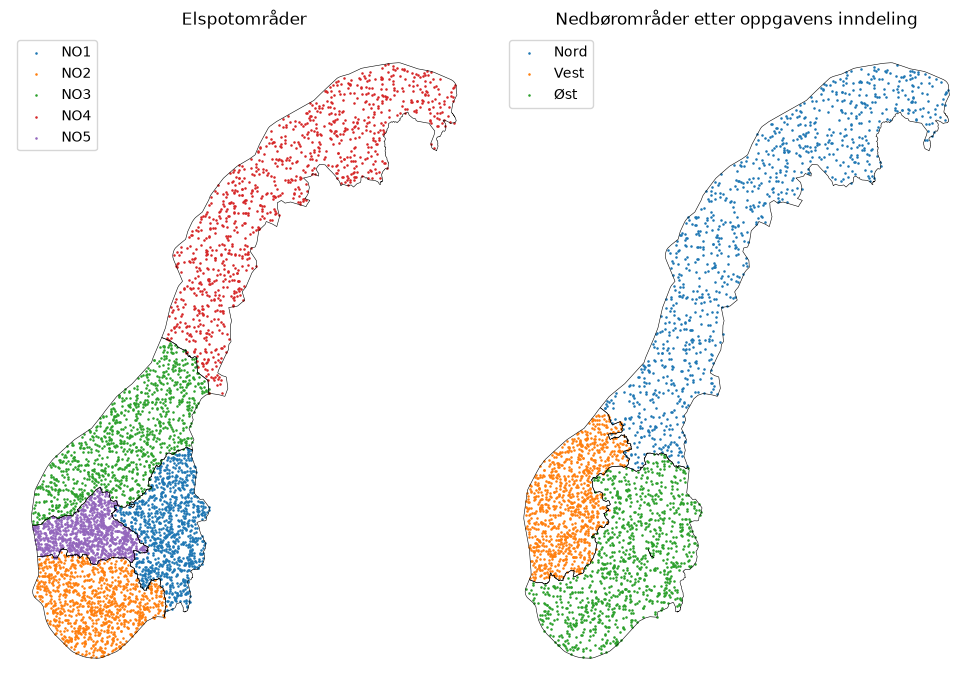

In [4]:
# To kart gjør det mulig å kontrollere de overlappende områdeinndelingene hver for seg.
fig, axes = plt.subplots(1, 2, figsize=(10, 7))
for ax, labels, title in [
    (axes[0], ["NO1", "NO2", "NO3", "NO4", "NO5"], "Elspotområder"),
    (axes[1], ["Øst", "Vest", "Nord"], "Nedbørområder etter oppgavens inndeling"),
]:
    regions.loc[regions["region"].isin(labels)].boundary.plot(ax=ax, color="black", linewidth=0.4)
    points.loc[points["region"].isin(labels)].plot(
        ax=ax, column="region", categorical=True, legend=True, markersize=0.7,
    )
    ax.set_title(title)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

## 3. Hent ERA5-værdata for en region

Funksjonen tar region og datointervall, slår opp koordinatene og henter timevis temperatur (°C) og nedbør (mm) fra [Open-Meteos historikk-API](https://open-meteo.com/en/docs/historical-weather-api), med **ERA5** og **UTC**.

API-et avviste forsøket med alle 1000 punktene i én forespørsel som for stort. Vi bruker derfor grupper på 100. Hver gruppe og det samlede resultatet lagres under `no_sync/weather/`, slik at nedlastingen kan gjenbrukes.

In [1]:
from pathlib import Path
import requests
import pandas as pd
import time


def download_weather(region, start_date, end_date, batch_size=100):
    """Hent timevis ERA5-temperatur og nedbør for regionens lagrede punkter."""
    root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    locations = pd.read_csv(root / "data/geography/weather_locations.csv")
    locations = locations.loc[locations["region"].eq(region)].sort_values("point_id")
    if locations.empty:
        raise ValueError(f"Ukjent region: {region}")
    start, end = pd.Timestamp(start_date), pd.Timestamp(end_date)
    if start > end:
        raise ValueError("Startdato må være før eller lik sluttdato.")
    start_date, end_date = start.strftime("%Y-%m-%d"), end.strftime("%Y-%m-%d")
    expected_times = pd.date_range(start_date, end + pd.Timedelta(days=1),
                                   freq="h", inclusive="left", tz="UTC")
    folder = root / "no_sync/weather"
    folder.mkdir(parents=True, exist_ok=True)
    saved_file = folder / f"{region}_era5_{start_date}_{end_date}.csv.gz"
    if saved_file.exists():
        print("Leser lagrede data:", saved_file.name)
        return pd.read_csv(saved_file, parse_dates=["time"])

    # Hent punktene i grupper og gjenbruk ferdige grupper ved en ny kjøring.
    parts_folder = folder / f"{region}_era5_{start_date}_{end_date}_parts"
    parts_folder.mkdir(exist_ok=True)
    frames = []
    for offset in range(0, len(locations), batch_size):
        batch = locations.iloc[offset:offset + batch_size]
        part_file = parts_folder / f"points_{batch.point_id.iloc[0]:04d}_{batch.point_id.iloc[-1]:04d}.csv.gz"
        if part_file.exists():
            frames.append(pd.read_csv(part_file, parse_dates=["time"]))
            continue
        params = {
            "latitude": ",".join(batch["latitude"].astype(str)),
            "longitude": ",".join(batch["longitude"].astype(str)),
            "start_date": start_date, "end_date": end_date,
            "hourly": "temperature_2m,precipitation",
            "models": "era5", "timezone": "GMT",
            "temperature_unit": "celsius", "precipitation_unit": "mm",
        }
        # En kort pause og eventuelt nytt forsøk hvis minuttgrensen er nådd.
        for attempt in range(3):
            response = requests.post("https://archive-api.open-meteo.com/v1/archive",
                                     data=params, timeout=(15, 180))
            if response.status_code != 429 or attempt == 2:
                break
            print("API-grensen er nådd. Venter 65 sekunder før nytt forsøk.", flush=True)
            time.sleep(65)
        if not response.ok:
            raise requests.HTTPError(f"Open-Meteo {response.status_code}: {response.text[:300]}",
                                     response=response)
        results = response.json()
        if isinstance(results, dict):
            results = [results]
        assert len(results) == len(batch), "Feil antall punkter i API-svaret."

        # Behold én rad per punkt og time, koblet til punkt-ID i koordinatfilen.
        batch_frames = []
        for point_id, result in zip(batch["point_id"], results):
            assert result["hourly_units"]["temperature_2m"] == "°C"
            assert result["hourly_units"]["precipitation"] == "mm"
            frame = pd.DataFrame(result["hourly"])
            frame["time"] = pd.to_datetime(frame["time"], utc=True)
            assert pd.DatetimeIndex(frame["time"]).equals(expected_times), "Uventede tidsstempler."
            frame.insert(0, "point_id", point_id)
            batch_frames.append(frame)
        part = pd.concat(batch_frames, ignore_index=True)
        assert not part.isna().any().any(), "API-svaret har manglende verdier."
        part.to_csv(part_file, index=False, compression="gzip")
        frames.append(part)
        print(f"Lagret punkter {offset + 1}–{offset + len(batch)} av {len(locations)}.", flush=True)
        time.sleep(2)
    data = pd.concat(frames, ignore_index=True)
    data.to_csv(saved_file, index=False, compression="gzip")
    print("Lagret:", saved_file.name)
    return data

In [2]:
# 2024 er et skuddår: 366 dager × 24 timer = 8784 timer per punkt.
weather_no3 = download_weather("NO3", "2024-01-01", "2024-12-31")
assert weather_no3["point_id"].nunique() == 1000
assert weather_no3.groupby("point_id").size().eq(8784).all()
assert not weather_no3.duplicated(["point_id", "time"]).any()
assert not weather_no3.isna().any().any()
print("Antall punkter:", weather_no3["point_id"].nunique())
print("Timer per punkt:", 8784)
print("Antall rader:", len(weather_no3))
weather_no3.head()

Lagret punkter 1–100 av 1000.


Lagret punkter 101–200 av 1000.


API-grensen er nådd. Venter 65 sekunder før nytt forsøk.


Lagret punkter 201–300 av 1000.


Lagret punkter 301–400 av 1000.


API-grensen er nådd. Venter 65 sekunder før nytt forsøk.


... (7 outputs left out)

Lagret punkter 901–1000 av 1000.


Lagret: NO3_era5_2024-01-01_2024-12-31.csv.gz


Antall punkter: 1000
Timer per punkt: 8784
Antall rader: 8784000


,point_id,time,temperature_2m,precipitation
0,1,2024-01-01 00:00:00+00:00,-7.3,0.0
1,1,2024-01-01 01:00:00+00:00,-7.6,0.0
2,1,2024-01-01 02:00:00+00:00,-7.8,0.0
3,1,2024-01-01 03:00:00+00:00,-7.9,0.0
4,1,2024-01-01 04:00:00+00:00,-7.8,0.0
